In [ ]:
import pandas as pd
df = pd.read_csv('/content/city_day.csv')
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
# Total rows and columns
print("Dataset Shape:", df.shape)
# Information about columns
df.info()
# Statistical summary
df.describe()

Dataset Shape: (29531, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [ ]:
# Count missing values
missing_values = df.isnull().sum()
# Calculate missing percentage
missing_percentage = (missing_values / len(df)) * 100
# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})
missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


In [ ]:
# Remove Xylene column
df = df.drop(columns=['Xylene'])
# Remove rows where target AQI is missing
df = df.dropna(subset=['AQI'])
# Fill missing numerical values with median
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
# Check missing values again
print(df.isnull().sum())

City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
AQI           0
AQI_Bucket    0
dtype: int64


In [ ]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])
# Extract useful date information
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
# Display the updated dataset
df[['Date', 'Year', 'Month', 'Day']].head()

,Date,Year,Month,Day
28,2015-01-29,2015,1,29
29,2015-01-30,2015,1,30
30,2015-01-31,2015,1,31
31,2015-02-01,2015,2,1
32,2015-02-02,2015,2,2


In [ ]:
# Select input features
X = df.drop(columns=['AQI', 'AQI_Bucket', 'Date'])
# Select target variable
y = df['AQI']
# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
# Display input columns
print("\nInput Features:")
print(X.columns.tolist())

Features Shape: (24850, 15)
Target Shape: (24850,)

Input Features:
['City', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Year', 'Month', 'Day']


In [ ]:
# Convert categorical City column into numerical columns
X = pd.get_dummies(X, columns=['City'], dtype=int)
# Display updated features
print("Updated Features Shape:", X.shape)
# Display first 5 rows
X.head()

Updated Features Shape: (24850, 40)


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,...,City_Jorapokhar,City_Kochi,City_Kolkata,City_Lucknow,City_Mumbai,City_Patna,City_Shillong,City_Talcher,City_Thiruvananthapuram,City_Visakhapatnam
28,83.13,96.18,6.93,28.71,33.72,16.31,6.93,49.52,59.76,0.02,...,0,0,0,0,0,0,0,0,0,0
29,79.84,96.18,13.85,28.68,41.08,16.31,13.85,48.49,97.07,0.04,...,0,0,0,0,0,0,0,0,0,0
30,94.52,96.18,24.39,32.66,52.61,16.31,24.39,67.39,111.33,0.24,...,0,0,0,0,0,0,0,0,0,0
31,135.99,96.18,43.48,42.08,84.57,16.31,43.48,75.23,102.70,0.40,...,0,0,0,0,0,0,0,0,0,0
32,178.33,96.18,54.56,35.31,72.80,16.31,54.56,55.04,107.38,0.46,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Sort data chronologically
df = df.sort_values(by='Date')
# Recreate X and y after sorting
X = df.drop(columns=['AQI', 'AQI_Bucket', 'Date'])
X = pd.get_dummies(X, columns=['City'], dtype=int)
y = df['AQI']
# Split based on chronological order (80:20)
split_index = int(len(df) * 0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (19880, 40)
Testing Features: (4970, 40)
Training Target: (19880,)
Testing Target: (4970,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
# Numerical and categorical columns
numeric_features = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx',
    'NH3', 'CO', 'SO2', 'O3', 'Benzene',
    'Toluene', 'Year', 'Month', 'Day'
]
categorical_features = ['City']
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
# Combine both
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Original features (before One-Hot Encoding)
X = df.drop(columns=['AQI', 'AQI_Bucket', 'Date'])
y = df['AQI']

# Chronological train-test split
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Define four regression models
models = {
    'Linear Regression': LinearRegression(),
    'KNN Regression': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,22.098082,1083.817163,32.921379,0.866148
1,KNN Regression,28.762656,2074.001272,45.541204,0.743860
2,Decision Tree,24.768612,1834.670423,42.833053,0.773417
3,Random Forest,16.699004,760.927280,27.584910,0.906025


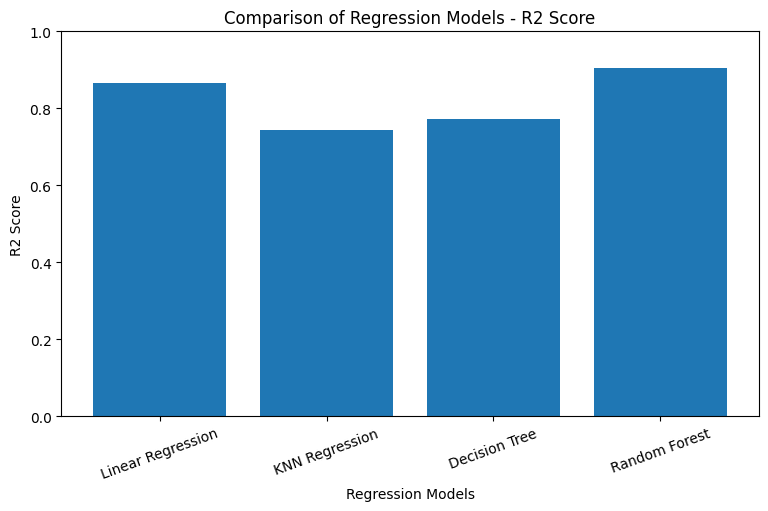

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(results_df['Model'], results_df['R2 Score'])

plt.title('Comparison of Regression Models - R2 Score')
plt.xlabel('Regression Models')
plt.ylabel('R2 Score')

plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

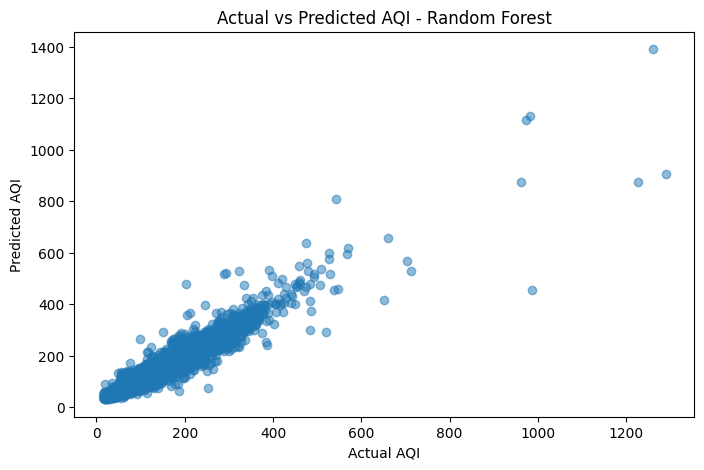

In [ ]:
# Get the trained Random Forest pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Plot actual vs predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.5)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI - Random Forest")

plt.show()

In [ ]:
# Extract trained Random Forest model
trained_rf = rf_model.named_steps['model']

# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get feature importance
importance = trained_rf.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
print(feature_importance.head(10))

         Feature  Importance
0     num__PM2.5    0.473101
6        num__CO    0.376814
2        num__NO    0.036781
1      num__PM10    0.035035
8        num__O3    0.013516
4       num__NOx    0.011221
3       num__NO2    0.008879
7       num__SO2    0.008513
13      num__Day    0.006937
10  num__Toluene    0.006464


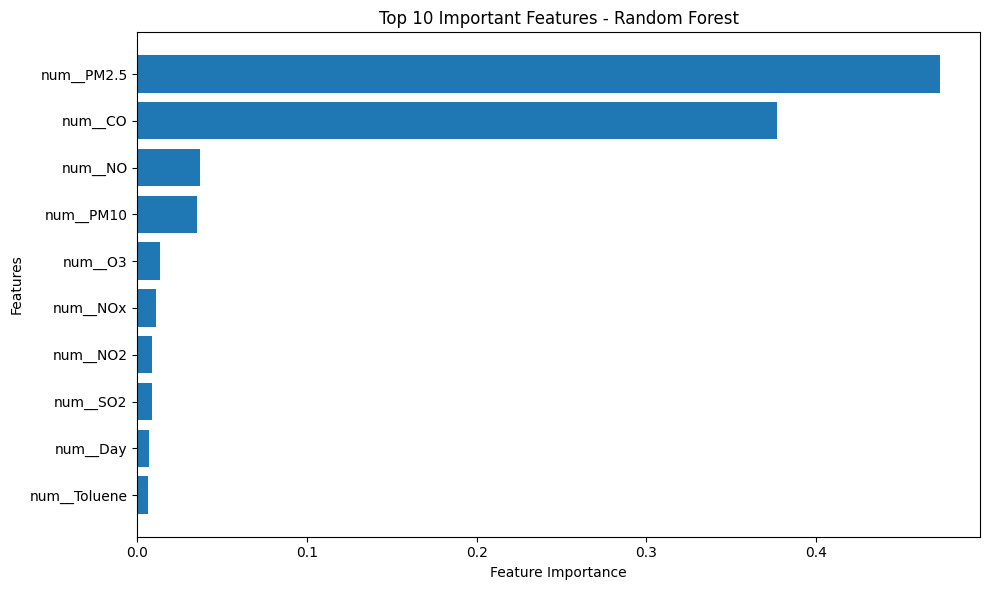

In [ ]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10).sort_values(
    by='Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [ ]:
df[col] = df[col].fillna(df[col].median())

In [ ]:
import pandas as pd

# Reload original dataset
df = pd.read_csv('/content/city_day.csv')

# Remove Xylene column
df = df.drop(columns=['Xylene'])

# Remove rows where target AQI is missing
df = df.dropna(subset=['AQI'])

# Convert Date into datetime
df['Date'] = pd.to_datetime(df['Date'])

# Sort data chronologically
df = df.sort_values(by='Date').reset_index(drop=True)

# Extract date features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

# Separate input and target
X = df.drop(columns=['AQI', 'AQI_Bucket', 'Date'])
y = df['AQI']

# Chronological 80:20 split
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Training data: (19880, 15)
Testing data: (4970, 15)
Missing values in training: 24180
Missing values in testing: 3973


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical columns
numeric_features = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx',
    'NH3', 'CO', 'SO2', 'O3', 'Benzene',
    'Toluene', 'Year', 'Month', 'Day'
]

# Categorical column
categorical_features = ['City']

# Process numerical data
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Process categorical data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Leakage-safe preprocessing pipeline created!")

Leakage-safe preprocessing pipeline created!


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    'Linear Regression': LinearRegression(),
    'KNN Regression': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train using training data only
    pipeline.fit(X_train, y_train)

    # Predict using test data
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,22.021851,1078.732660,32.844066,0.866776
1,KNN Regression,28.714487,2066.955421,45.463781,0.744730
2,Decision Tree,25.165392,1932.700201,43.962486,0.761311
3,Random Forest,16.618596,760.736983,27.581461,0.906049


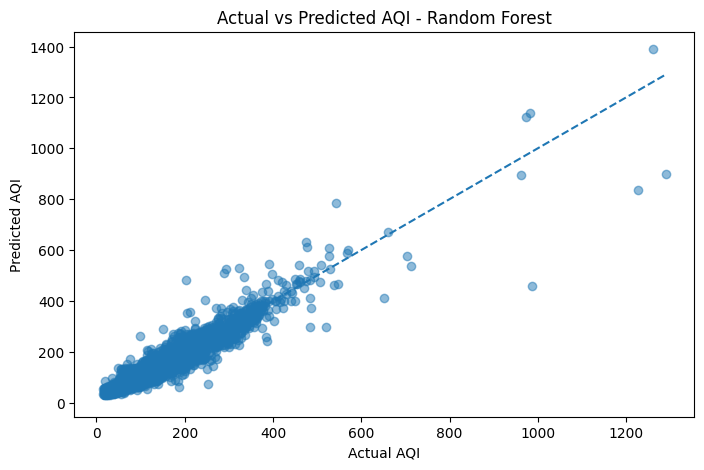

In [ ]:
# Get leakage-safe Random Forest model
rf_model = trained_models['Random Forest']

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, rf_predictions, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI - Random Forest")
plt.show()

In [ ]:
# Extract trained Random Forest model
trained_rf = rf_model.named_steps['model']

# Get feature names
feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get importance scores
importance = trained_rf.feature_importances_

# Create table
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10
feature_importance.head(10)

,Feature,Importance
0,num__PM2.5,0.473269
6,num__CO,0.376502
2,num__NO,0.036913
1,num__PM10,0.035200
8,num__O3,0.013317
4,num__NOx,0.011368
3,num__NO2,0.008752
7,num__SO2,0.008632
13,num__Day,0.006962
10,num__Toluene,0.006732


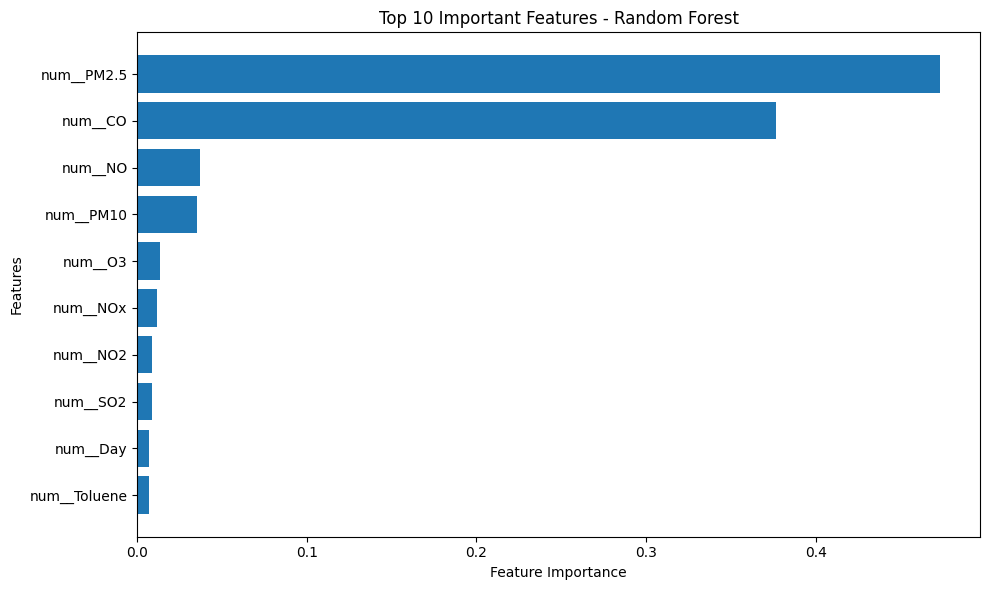

In [ ]:
top_features = feature_importance.head(10).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [ ]:
#city wise model performance
from sklearn.metrics import mean_absolute_error, r2_score

# Get predictions from Random Forest
rf_predictions = rf_model.predict(X_test)

# Create a result table
city_results = pd.DataFrame({
    'City': X_test['City'].values,
    'Actual_AQI': y_test.values,
    'Predicted_AQI': rf_predictions
})

# Calculate performance for each city
city_performance = city_results.groupby('City').apply(
    lambda group: pd.Series({
        'Records': len(group),
        'MAE': mean_absolute_error(
            group['Actual_AQI'],
            group['Predicted_AQI']
        ),
        'R2 Score': r2_score(
            group['Actual_AQI'],
            group['Predicted_AQI']
        ) if len(group) >= 2 else float('nan')
    }),
    include_groups=False
).reset_index()

# Display results
city_performance.sort_values(
    by='MAE',
    ascending=True
)

,City,Records,MAE,R2 Score
4,Bengaluru,208.0,6.453173,0.796606
24,Thiruvananthapuram,208.0,7.739183,0.786718
14,Hyderabad,208.0,8.206875,0.895352
20,Mumbai,208.0,8.962163,0.941893
11,Ernakulam,153.0,10.619673,0.471192
18,Kolkata,208.0,11.241538,0.956010
22,Shillong,142.0,11.832746,0.758832
15,Jaipur,208.0,11.997452,0.595836
25,Visakhapatnam,202.0,13.330644,0.790919
8,Chennai,209.0,14.081244,0.089465


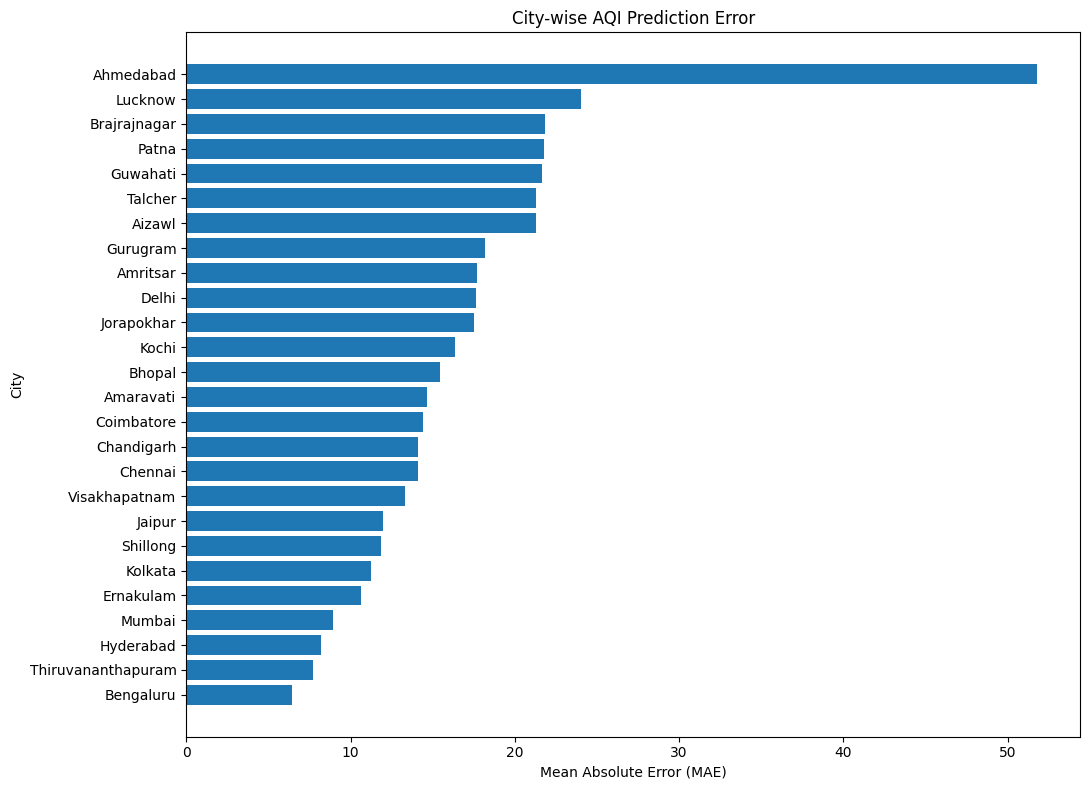

In [ ]:
import matplotlib.pyplot as plt

city_sorted = city_performance.sort_values(
    by='MAE',
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    city_sorted['City'],
    city_sorted['MAE']
)

plt.xlabel('Mean Absolute Error (MAE)')
plt.ylabel('City')
plt.title('City-wise AQI Prediction Error')

plt.tight_layout()
plt.show()

In [ ]:
# Check actual AQI distribution city-wise
city_analysis = city_results.groupby('City').agg(
    Actual_AQI_Mean=('Actual_AQI', 'mean'),
    Actual_AQI_Min=('Actual_AQI', 'min'),
    Actual_AQI_Max=('Actual_AQI', 'max'),
    Actual_AQI_Std=('Actual_AQI', 'std'),
    Records=('Actual_AQI', 'count')
).reset_index()

# Show selected cities
city_analysis[
    city_analysis['City'].isin([
        'Ahmedabad',
        'Aizawl',
        'Chennai',
        'Bengaluru',
        'Mumbai'
    ])
]

,City,Actual_AQI_Mean,Actual_AQI_Min,Actual_AQI_Max,Actual_AQI_Std,Records
0,Ahmedabad,250.990050,74.0,1291.0,218.464322,201
1,Aizawl,34.765766,18.0,92.0,19.969957,111
4,Bengaluru,79.980769,40.0,137.0,18.600286,208
8,Chennai,80.583732,50.0,230.0,22.982098,209
20,Mumbai,114.009615,46.0,283.0,59.156959,208


In [ ]:
# Calculate absolute prediction error
city_results['Absolute_Error'] = abs(
    city_results['Actual_AQI'] -
    city_results['Predicted_AQI']
)

# Filter Ahmedabad records
ahmedabad_errors = city_results[
    city_results['City'] == 'Ahmedabad'
].copy()

# Show 10 records with highest errors
ahmedabad_errors = ahmedabad_errors.sort_values(
    by='Absolute_Error',
    ascending=False
)

ahmedabad_errors.head(10)

,City,Actual_AQI,Predicted_AQI,Absolute_Error
2415,Ahmedabad,988.0,458.34,529.66
1705,Ahmedabad,1291.0,900.17,390.83
1675,Ahmedabad,1226.0,836.06,389.94
1196,Ahmedabad,204.0,481.02,277.02
1673,Ahmedabad,543.0,785.46,242.46
1438,Ahmedabad,652.0,413.00,239.00
27,Ahmedabad,293.0,527.41,234.41
126,Ahmedabad,520.0,296.93,223.07
1427,Ahmedabad,322.0,530.32,208.32
1041,Ahmedabad,483.0,297.38,185.62


In [ ]:
# Separate test records into AQI categories
city_results['AQI_Category'] = pd.cut(
    city_results['Actual_AQI'],
    bins=[-float('inf'), 100, 200, 300, float('inf')],
    labels=[
        '0-100',
        '101-200',
        '201-300',
        'Above 300'
    ]
)

# Calculate performance in each category
aqi_performance = city_results.groupby(
    'AQI_Category',
    observed=False
).apply(
    lambda group: pd.Series({
        'Records': len(group),
        'MAE': mean_absolute_error(
            group['Actual_AQI'],
            group['Predicted_AQI']
        ),
        'RMSE': np.sqrt(
            mean_squared_error(
                group['Actual_AQI'],
                group['Predicted_AQI']
            )
        )
    }),
    include_groups=False
).reset_index()

aqi_performance

,AQI_Category,Records,MAE,RMSE
0,0-100,2623.0,11.779119,16.092826
1,101-200,1684.0,16.914454,23.405523
2,201-300,381.0,32.526798,45.833367
3,Above 300,282.0,38.372837,69.920641


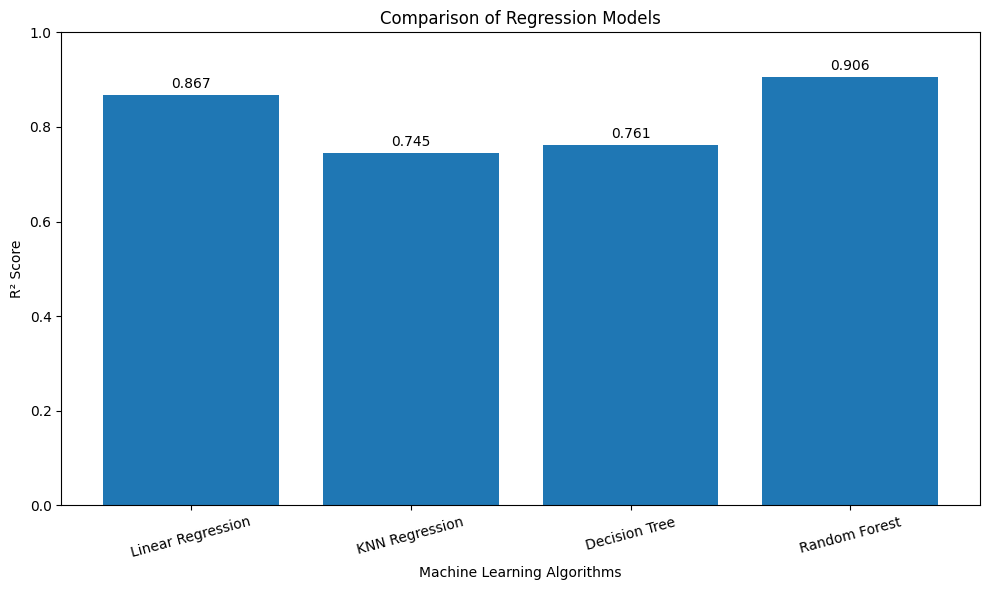

In [ ]:
import matplotlib.pyplot as plt

models = [
    'Linear Regression',
    'KNN Regression',
    'Decision Tree',
    'Random Forest'
]

r2_scores = [
    0.866776,
    0.744730,
    0.761311,
    0.906049
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, r2_scores)

plt.title('Comparison of Regression Models')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('R² Score')
plt.ylim(0, 1)

# Display values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.015,
        f'{height:.3f}',
        ha='center'
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()